<a href="https://colab.research.google.com/github/Naylet92/Estudio_ambiental/blob/main/Quila/QLA_2010_construir_numpy_8capas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Sierra de Quila 2010
### Construcción del arrays NumPy de 8 capas por sensor + RobustScaler/Standard Scaler + PCA

Pasos:
1. Leer los GeoTIFF de 4 bandas (`NDVI, TC_Brightness, TC_Greenness, TC_Wetness`).
2. Construir el array `(4 bandas, alto, ancho)` por temporada.
3. Combinar las temporadas de seca y húmeda en un solo array, esto ya sería las`(8 bandas, alto, ancho)` por sensor.
4. Aplicar el método `RobustScaler` (no acepta valores NaN), entonces se filtraron los pixeles para que no falle o contamine la mediana/IQR.Para eso se usa el método `mask_valida.`
5. Aplicar el método `StandardScaler` (no acepta valores NaN), entonces se filtraron los pixeles para que no falle o contamine la promedio/SD.Para eso se usa el método `mask_valida.`
6. Guardar el array escalado (`.npy`) y el orden de capas (`.json`) por sensor.
7. Realizar PCA en cada conjunto
8. Guardar los resultados de PCA en NumPy array

Notas: versión preliminar, falta optimizar para reducir la redundancia del código


In [8]:
PREFIJO     = 'QLA'
NOMBRE      = 'Sierra_Quila'

# Ruta de la carpeta de Drive donde estan los .tif exportados
#RUTA_TIF = '/content/drive/MyDrive/ANP/Landsat/SVerde_Landsat/SVD_tif-2000'
RUTA_TIF = '/content/drive/MyDrive/Colab Data NDC 2020'

AÑO        = 2010

## En este año solo L7 presenta datos de temporada seca y humada
#SENSORES   = ['L7', 'L5']
SENSORES   = ['L7']
TEMPORADAS = ['seca', 'humeda']
NOMBRES_BANDAS = ['NDVI', 'TC_Brightness', 'TC_Greenness', 'TC_Wetness']

# Carpeta local donde se guardaran los .npy y .json de salida
#RUTA_SALIDA ='/content/drive/MyDrive/ANP/Landsat/SVerde_Landsat/SVD_tif-2000/Nympy2000'
RUTA_SALIDA = '/content/drive/MyDrive/Colab Data NDC 2020/Numpy'

In [2]:
import os
import glob
import json
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler, StandardScaler
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
def buscar_tif(patron, avisar_si_hay_varios=True):     # si hay mas de uno agarramos el mas nuevo, pero igual avisamos
    candidatos = glob.glob(patron)
    if len(candidatos) == 0:
        raise FileNotFoundError(f"No se encontro tif con patron: {patron}")

    if len(candidatos) > 1:
        candidatos.sort(key=os.path.getmtime, reverse=True)
        if avisar_si_hay_varios:
            print(f"  Aviso: {len(candidatos)} archivos coinciden, usando el mas reciente: {os.path.basename(candidatos[0])}")

    return candidatos[0]


def encontrar_tif(prefijo, año, sensor, temporada, carpeta):
    patron = os.path.join(carpeta, f"{prefijo}_{año}_{sensor}_{temporada}.tif")
    candidatos = [f for f in glob.glob(patron) if 'bandas_corr' not in f]      #descarto los de bandas_corr
    if not candidatos:
        raise FileNotFoundError(f"No se encontro tif para {sensor} {temporada} con patron: {patron}")
    if len(candidatos) > 1:
        candidatos.sort(key=os.path.getmtime, reverse=True)
        print(f"  Aviso: {len(candidatos)} archivos coinciden para {sensor}-{temporada}, usando el mas reciente")
    return candidatos[0]


def leer_tif_a_array(path):       # devuelve (bandas, H, W) en float32 + el profile por si hace falta despues
    with rasterio.open(path) as src:
        arr = src.read().astype('float32')
        if src.nodata is not None and not np.isnan(src.nodata):
            arr[arr == src.nodata] = np.nan
        perfil = src.profile
    return arr, perfil


def construir_array_8capas(sensor, prefijo, año, carpeta, temporadas=TEMPORADAS, nombres_bandas=NOMBRES_BANDAS):
    partes = []
    orden_capas = []
    perfil_ref = None

    for temporada in temporadas:
        path = encontrar_tif(prefijo, año, sensor, temporada, carpeta)
        arr, perfil = leer_tif_a_array(path)

        if perfil_ref is None:
            perfil_ref = perfil
        else:  # las dos temporadas tienen que tener el mismo shape, sino algo se exporto mal en Earth Engine
            dim_ref = (perfil_ref['height'], perfil_ref['width'])
            if arr.shape[1:] != dim_ref:
                raise ValueError(f"Dimensiones de {sensor}-{temporada} {arr.shape[1:]} no coinciden con {dim_ref}")

        partes.append(arr)
        for b in nombres_bandas:
            orden_capas.append(f"{b}_{temporada}")

    array_8 = np.concatenate(partes, axis=0)
    return array_8, orden_capas, perfil_ref


def aplicar_robust_scaler(array_8capas):
    n_bandas, H, W = array_8capas.shape
    X = array_8capas.reshape(n_bandas, H * W).T          # (n_pixeles, 8)
    mask_valida = ~np.isnan(X).any(axis=1)

    if mask_valida.sum() == 0:
        raise ValueError("Todos los pixeles son NaN; no hay datos validos para escalar.")

    scaler = RobustScaler()
    X_escalado = np.full_like(X, np.nan)
    X_escalado[mask_valida] = scaler.fit_transform(X[mask_valida])

    array_escalado = X_escalado.T.reshape(n_bandas, H, W)
    return array_escalado, scaler

def aplicar_standard_scaler(array_8capas):
    n_bandas, H, W = array_8capas.shape
    X = array_8capas.reshape(n_bandas, H * W).T          # (n_pixeles, 8)
    mask_valida = ~np.isnan(X).any(axis=1)

    if mask_valida.sum() == 0:
        raise ValueError("Todos los pixeles son NaN; no hay datos validos para escalar.")

    scaler = StandardScaler()
    X_escalado = np.full_like(X, np.nan)
    X_escalado[mask_valida] = scaler.fit_transform(X[mask_valida])

    array_escalado = X_escalado.T.reshape(n_bandas, H, W)
    return array_escalado, scaler



## Ejecutar RobustScaler y StandardScaler para cada sensor

In [9]:
os.makedirs(RUTA_SALIDA, exist_ok=True)

resultados_rs = {}
resultados_ss = {}

for sensor in SENSORES:
    print(f"\nProcesando sensor {sensor}...")
    array_8, orden_capas, perfil = construir_array_8capas(sensor, PREFIJO, AÑO, RUTA_TIF)
    print(f"  Array combinado (seca+humeda): shape = {array_8.shape}")

    array_escalado_rs, scaler_rs = aplicar_robust_scaler(array_8)
    array_escalado_ss, scaler_ss = aplicar_standard_scaler(array_8)
    print(f"  Array escalado (RS): shape = {array_escalado_rs.shape}, "
          f"NaN preservados = {np.isnan(array_escalado_rs).sum()}")
    print(f"  Array escalado (SS): shape = {array_escalado_ss.shape}, "
          f"NaN preservados = {np.isnan(array_escalado_ss).sum()}")

    resultados_rs[sensor] = {
        'array': array_escalado_rs,
        'orden_capas': orden_capas,
        'perfil': perfil,
        'scaler': scaler_rs,
    }

    resultados_ss[sensor] = {
        'array': array_escalado_ss,
        'orden_capas': orden_capas,
        'perfil': perfil,
        'scaler': scaler_ss,
    }

    ruta_npy_rs  = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_8capas_escalado_rs.npy')
    ruta_npy_ss  = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_8capas_escalado_ss.npy')
    ruta_json = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_8capas_orden.json')

    np.save(ruta_npy_rs, array_escalado_rs)
    np.save(ruta_npy_ss, array_escalado_ss)

    with open(ruta_json, 'w') as f:
        json.dump(orden_capas, f, ensure_ascii=False, indent=2)

    print(f"  Guardado: {ruta_npy_rs}")
    print(f"  Guardado: {ruta_npy_ss}")
    print(f"  Guardado: {ruta_json}")

print("\nOrden de capas (igual para todos los sensores y tipos de transformación):")
print(resultados_rs[SENSORES[0]]['orden_capas'])



Procesando sensor L7...
  Array combinado (seca+humeda): shape = (8, 1103, 1330)
  Array escalado (RS): shape = (8, 1103, 1330), NaN preservados = 35560
  Array escalado (SS): shape = (8, 1103, 1330), NaN preservados = 35560
  Guardado: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_8capas_escalado_rs.npy
  Guardado: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_8capas_escalado_ss.npy
  Guardado: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_8capas_orden.json

Orden de capas (igual para todos los sensores y tipos de transformación):
['NDVI_seca', 'TC_Brightness_seca', 'TC_Greenness_seca', 'TC_Wetness_seca', 'NDVI_humeda', 'TC_Brightness_humeda', 'TC_Greenness_humeda', 'TC_Wetness_humeda']


## Verificación rápida (Robust Scaler)
Estadísticas básicas del array escalado para confirmar que RobustScaler funcionó como se espera (mediana ≈ 0, IQR ≈ 1 por capa, ignorando NaN).

Robust Scaler
L7
----------------------------------------
NDVI_seca: promedio=0.2165  mediana=0.0000  SD=1.0367 IQR=1.0000  min=-7.9068  max=5.2844
TC_Brightness_seca: promedio=0.1111  mediana=0.0000  SD=0.8221 IQR=1.0000  min=-3.9073  max=16.9105
TC_Greenness_seca: promedio=0.1900  mediana=0.0000  SD=0.9892 IQR=1.0000  min=-33.7598  max=7.0842
TC_Wetness_seca: promedio=0.0092  mediana=0.0000  SD=0.8093 IQR=1.0000  min=-17.9974  max=3.8091
NDVI_humeda: promedio=-0.1509  mediana=0.0000  SD=0.8151 IQR=1.0000  min=-7.8343  max=1.3566
TC_Brightness_humeda: promedio=0.0317  mediana=0.0000  SD=0.8496 IQR=1.0000  min=-5.0799  max=16.5830
TC_Greenness_humeda: promedio=-0.0026  mediana=0.0000  SD=0.8604 IQR=1.0000  min=-8.6618  max=8.9742
TC_Wetness_humeda: promedio=-0.0896  mediana=0.0000  SD=0.8726 IQR=1.0000  min=-16.3725  max=4.6152

L7
----------------------------------------


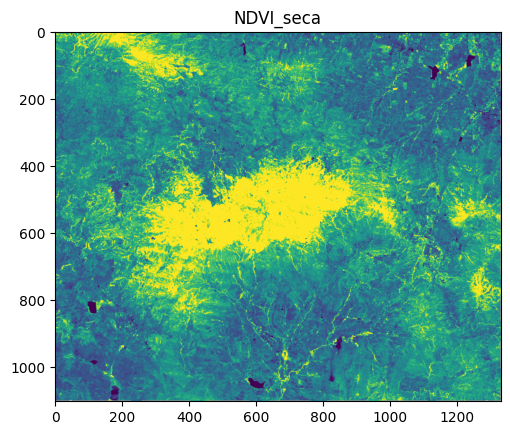

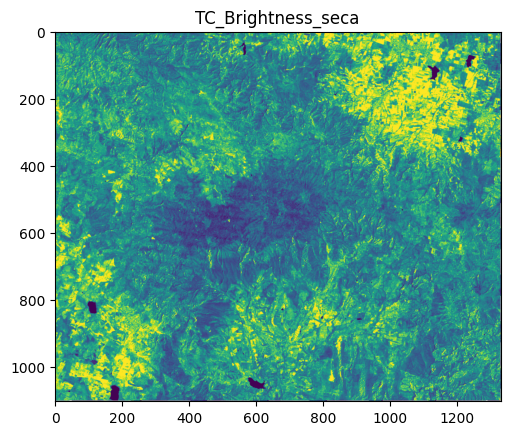

In [10]:
for sensor in SENSORES:
    arr = resultados_rs[sensor]['array']
    orden = resultados_rs[sensor]['orden_capas']
    print(f"Robust Scaler\n{sensor}")
    print("-" * 40)

    for i in range(len(orden)):
        nombre = orden[i]
        capa = arr[i]
        valida = capa[~np.isnan(capa)]
        mediana = np.median(valida)
        promedio = np.mean(valida)
        sd = np.std(valida)
        q1 = np.percentile(valida, 25)
        q3 = np.percentile(valida, 75)
        print(f"{nombre}: promedio={promedio:.4f}  mediana={mediana:.4f}  SD={sd:.4f} IQR={q3 - q1:.4f}  min={valida.min():.4f}  max={valida.max():.4f}")

for sensor in SENSORES:
    arr = resultados_rs[sensor]['array']
    orden = resultados_rs[sensor]['orden_capas']
    print(f"\n{sensor}")
    print("-" * 40)

    plt.imshow(arr[0,:,:], vmin=-2, vmax=2)
    plt.title(orden[0])
    plt.show()

    plt.imshow(arr[1,:,:], vmin=-2, vmax=2)
    plt.title(orden[1])
    plt.show()



## Verificación rápida (Standard Scaler)
Estadísticas básicas del array escalado para confirmar que StandardScaler funcionó como se espera (primedio ≈ 0, SD ≈ 1 por capa, ignorando NaN).

Standard Scaler
L7
----------------------------------------
NDVI_seca: promedio=0.0000  mediana=-0.2089  SD=1.0000 IQR=0.9646  min=-7.8360  max=4.8886
TC_Brightness_seca: promedio=-0.0000  mediana=-0.1352  SD=1.0000 IQR=1.2165  min=-4.8883  max=20.4356
TC_Greenness_seca: promedio=-0.0000  mediana=-0.1921  SD=1.0000 IQR=1.0109  min=-34.3209  max=6.9695
TC_Wetness_seca: promedio=0.0000  mediana=-0.0113  SD=1.0000 IQR=1.2356  min=-22.2485  max=4.6951
NDVI_humeda: promedio=-0.0000  mediana=0.1851  SD=1.0000 IQR=1.2268  min=-9.4263  max=1.8495
TC_Brightness_humeda: promedio=0.0000  mediana=-0.0373  SD=1.0000 IQR=1.1770  min=-6.0166  max=19.4816
TC_Greenness_humeda: promedio=-0.0000  mediana=0.0030  SD=1.0000 IQR=1.1623  min=-10.0643  max=10.4335
TC_Wetness_humeda: promedio=-0.0000  mediana=0.1027  SD=1.0000 IQR=1.1460  min=-18.6596  max=5.3915

L7
----------------------------------------


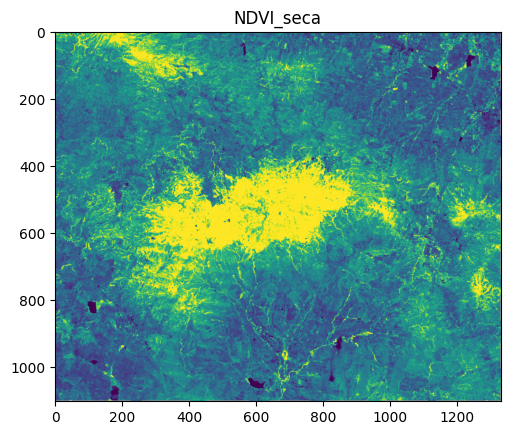

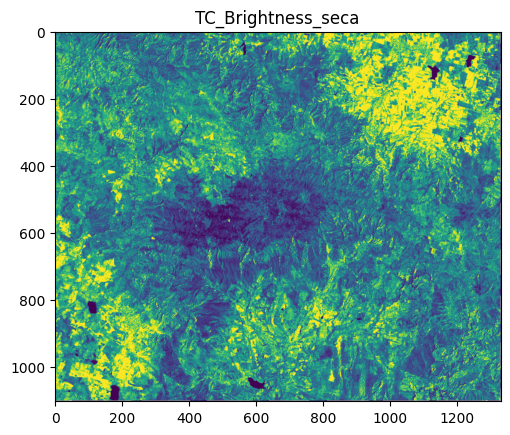

In [11]:
for sensor in SENSORES:
    arr = resultados_ss[sensor]['array']
    orden = resultados_ss[sensor]['orden_capas']
    print(f"Standard Scaler\n{sensor}")
    print("-" * 40)

    for i in range(len(orden)):
        nombre = orden[i]
        capa = arr[i]
        valida = capa[~np.isnan(capa)]
        mediana = np.median(valida)
        promedio = np.mean(valida)
        sd = np.std(valida)
        q1 = np.percentile(valida, 25)
        q3 = np.percentile(valida, 75)
        print(f"{nombre}: promedio={promedio:.4f}  mediana={mediana:.4f}  SD={sd:.4f} IQR={q3 - q1:.4f}  min={valida.min():.4f}  max={valida.max():.4f}")

for sensor in SENSORES:
    arr = resultados_ss[sensor]['array']
    orden = resultados_ss[sensor]['orden_capas']
    print(f"\n{sensor}")
    print("-" * 40)

    plt.imshow(arr[0,:,:], vmin=-2, vmax=2)
    plt.title(orden[0])
    plt.show()

    plt.imshow(arr[1,:,:], vmin=-2, vmax=2)
    plt.title(orden[1])
    plt.show()

# PCA con datos de RobustScaler

In [12]:
from sklearn.decomposition import PCA

# Initialize a dictionary to store PCA results
pca_resultados_rs = {}
pca_rs = PCA(n_components=6)

for sensor in ['L7']:
    print(f"\nApplying PCA for sensor {sensor}...")
    # Get the scaled array for the current sensor
    array_escalado = resultados_rs[sensor]['array']
    n_bands, H, W = array_escalado.shape

    # Reshape the array from (bands, H, W) to (pixels, bands)
    # and handle NaN values for PCA
    X = array_escalado.reshape(n_bands, H * W).T  # (n_pixels, n_bands)

    # Create a mask to identify valid (non-NaN) pixels
    mask_valida = ~np.isnan(X).any(axis=1)

    if mask_valida.sum() == 0:
        print(f"  Warning: No valid pixels found for sensor {sensor}. Skipping PCA.")
        pca_resultados_rs[sensor] = {
            'transformed_array': np.full_like(X, np.nan).reshape(H, W, 6).transpose(2,0,1),
            'pca_model': None,
            'mask_valida': mask_valida
        }
        continue

    # Fit PCA only on valid data
    X_valid = X[mask_valida]

    # Train (fit) PCA with 6 components only for L8
    if sensor == 'L7':
        pca_rs.fit(X_valid)
        print(f"  Explained variance ratio: {pca_rs.explained_variance_ratio_.sum():.4f}")

    # Transform the valid data
    X_pca_valid = pca_rs.transform(X_valid)

    # Create an output array for PCA results, initialized with NaNs
    X_pca = np.full((H * W, 6), np.nan, dtype=np.float32)
    # Place the transformed valid data back into the correct positions
    X_pca[mask_valida] = X_pca_valid

    # Reshape the PCA result back to image dimensions (components, H, W)
    array_pca = X_pca.T.reshape(6, H, W)

    pca_resultados_rs[sensor] = {
        'transformed_array': array_pca,
        'pca_model': pca_rs,
        'mask_valida': mask_valida,
        'orden_capas': pca_rs.get_feature_names_out()
    }

    print(f"  PCA applied. Transformed array shape: {array_pca.shape}")

    ruta_npy_pca_rs  = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_PCA6_rs.npy')
    ruta_npy_valid_rs  = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_PCA6_rs_valid_mask.npy')
    np.save(ruta_npy_pca_rs, array_pca)
    print(f"  Guardado PCA RS: {ruta_npy_pca_rs}")
    np.save(ruta_npy_valid_rs, mask_valida)
    print(f"  Guardado mascara validos RS: {ruta_npy_valid_rs}")

    ## orden de capas PCA es el mismo para RS y SS, se guarda solo una vez
    ruta_json_orden_pca = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_PCA6_orden.json')
    with open(ruta_json_orden_pca, 'w') as f:
        json.dump(pca_resultados_rs[sensor]['orden_capas'].tolist(), f, ensure_ascii=False, indent=2)



Applying PCA for sensor L7...
  Explained variance ratio: 0.9925
  PCA applied. Transformed array shape: (6, 1103, 1330)
  Guardado PCA RS: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_PCA6_rs.npy
  Guardado mascara validos RS: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_PCA6_rs_valid_mask.npy


### Verificación rapida PCA RS


L7
----------------------------------------
pca0: promedio=0.0000  mediana=-0.0888  SD=1.9143 IQR=2.3446  min=-38.8327  max=7.2386
pca1: promedio=-0.0000  mediana=-0.0311  SD=1.1334 IQR=1.2262  min=-9.8831  max=14.8064
pca2: promedio=-0.0000  mediana=-0.1313  SD=0.8405 IQR=1.0624  min=-6.0080  max=13.7063
pca3: promedio=-0.0000  mediana=-0.0228  SD=0.5680 IQR=0.6659  min=-7.2741  max=9.1211
pca4: promedio=-0.0000  mediana=-0.0582  SD=0.4548 IQR=0.5362  min=-6.3059  max=5.9873
pca5: promedio=-0.0000  mediana=-0.0145  SD=0.1999 IQR=0.2279  min=-1.8737  max=10.6474

L7
----------------------------------------


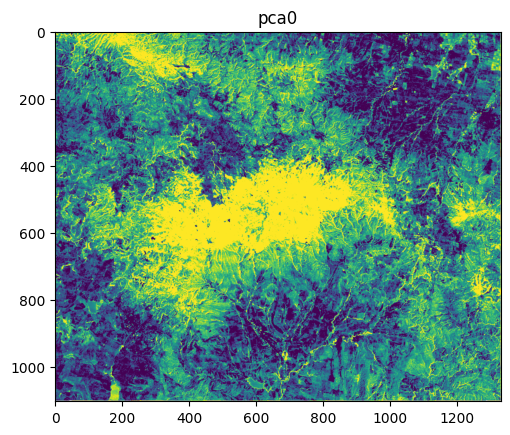

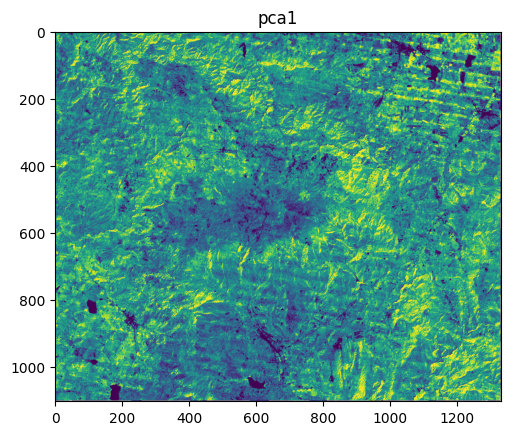

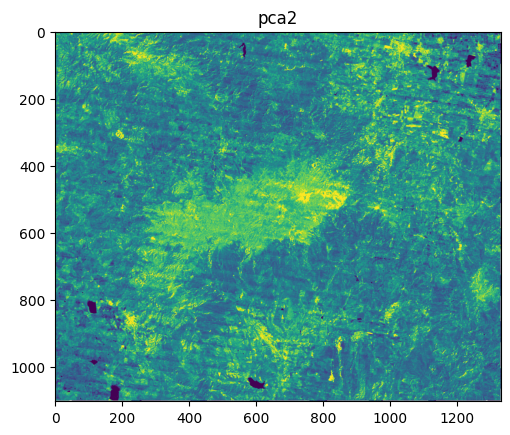

In [13]:
for sensor in SENSORES:
    arr = pca_resultados_rs[sensor]['transformed_array']
    orden = pca_resultados_rs[sensor]['orden_capas']
    print(f"\n{sensor}")
    print("-" * 40)

    for i in range(len(orden)):
        nombre = orden[i]
        capa = arr[i]
        valida = capa[~np.isnan(capa)]
        mediana = np.median(valida)
        promedio = np.mean(valida)
        sd = np.std(valida)
        q1 = np.percentile(valida, 25)
        q3 = np.percentile(valida, 75)
        print(f"{nombre}: promedio={promedio:.4f}  mediana={mediana:.4f}  SD={sd:.4f} IQR={q3 - q1:.4f}  min={valida.min():.4f}  max={valida.max():.4f}")


for sensor in SENSORES:
    arr = pca_resultados_rs[sensor]['transformed_array']
    orden = pca_resultados_rs[sensor]['orden_capas']
    print(f"\n{sensor}")
    print("-" * 40)

    plt.imshow(arr[0,:,:], vmin=-2.5, vmax=2.5)
    plt.title(orden[0])
    plt.show()

    plt.imshow(arr[1,:,:], vmin=-2.5, vmax=2.5)
    plt.title(orden[1])
    plt.show()

    plt.imshow(arr[2,:,:], vmin=-2.5, vmax=2.5)
    plt.title(orden[2])
    plt.show()

# PCA con datos de StandardScaler

In [14]:
# Initialize a dictionary to store PCA results
pca_resultados_ss = {}
pca_ss = PCA(n_components=6)

for sensor in ['L7']:
    print(f"\nApplying PCA for sensor {sensor}...")
    # Get the scaled array for the current sensor
    array_escalado = resultados_ss[sensor]['array']
    n_bands, H, W = array_escalado.shape

    # Reshape the array from (bands, H, W) to (pixels, bands)
    # and handle NaN values for PCA
    X = array_escalado.reshape(n_bands, H * W).T  # (n_pixels, n_bands)

    # Create a mask to identify valid (non-NaN) pixels
    mask_valida = ~np.isnan(X).any(axis=1)

    if mask_valida.sum() == 0:
        print(f"  Warning: No valid pixels found for sensor {sensor}. Skipping PCA.")
        pca_resultados_ss[sensor] = {
            'transformed_array': np.full_like(X, np.nan).reshape(H, W, 6).transpose(2,0,1),
            'pca_model': None,
            'mask_valida': mask_valida
        }
        continue

    # Fit PCA only on valid data
    X_valid = X[mask_valida]

    # Train (fit) PCA with 6 components only for L8
    if sensor == 'L7':
        pca_ss.fit(X_valid)
        print(f"  Explained variance ratio: {pca_ss.explained_variance_ratio_.sum():.4f}")

    # Transform the valid data
    X_pca_valid = pca_ss.transform(X_valid)

    # Create an output array for PCA results, initialized with NaNs
    X_pca = np.full((H * W, 6), np.nan, dtype=np.float32)
    # Place the transformed valid data back into the correct positions
    X_pca[mask_valida] = X_pca_valid

    # Reshape the PCA result back to image dimensions (components, H, W)
    array_pca = X_pca.T.reshape(6, H, W)

    pca_resultados_ss[sensor] = {
        'transformed_array': array_pca,
        'pca_model': pca_ss,
        'mask_valida': mask_valida,
        'orden_capas': pca_ss.get_feature_names_out()
    }

    print(f"  PCA applied. Transformed array shape: {array_pca.shape}")

    ruta_npy_pca_ss  = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_PCA6_ss.npy')
    ruta_npy_valid_ss  = os.path.join(RUTA_SALIDA, f'{PREFIJO}_{AÑO}_{sensor}_PCA6_ss_valid_mask.npy')
    np.save(ruta_npy_pca_ss, array_pca)
    print(f"  Guardado PCA SS: {ruta_npy_pca_ss}")
    np.save(ruta_npy_valid_ss, mask_valida)
    print(f"  Guardado mascara validos SS: {ruta_npy_valid_ss}")



Applying PCA for sensor L7...
  Explained variance ratio: 0.9932
  PCA applied. Transformed array shape: (6, 1103, 1330)
  Guardado PCA SS: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_PCA6_ss.npy
  Guardado mascara validos SS: /content/drive/MyDrive/Colab Data NDC 2020/Numpy/QLA_2010_L7_PCA6_ss_valid_mask.npy


### Verificaciín rapida PCA SS


L7
----------------------------------------
pca0: promedio=-0.0000  mediana=-0.0297  SD=2.1274 IQR=2.6994  min=-42.6096  max=7.7504
pca1: promedio=0.0000  mediana=-0.0198  SD=1.3434 IQR=1.4701  min=-11.6752  max=16.7280
pca2: promedio=-0.0000  mediana=-0.1513  SD=0.9010 IQR=1.1047  min=-8.1788  max=13.9657
pca3: promedio=0.0000  mediana=-0.0283  SD=0.6756 IQR=0.8207  min=-8.2825  max=10.3858
pca4: promedio=0.0000  mediana=-0.0679  SD=0.5381 IQR=0.6319  min=-7.2591  max=7.0469
pca5: promedio=0.0000  mediana=0.0116  SD=0.2388 IQR=0.2564  min=-7.2247  max=5.5591

L7
----------------------------------------


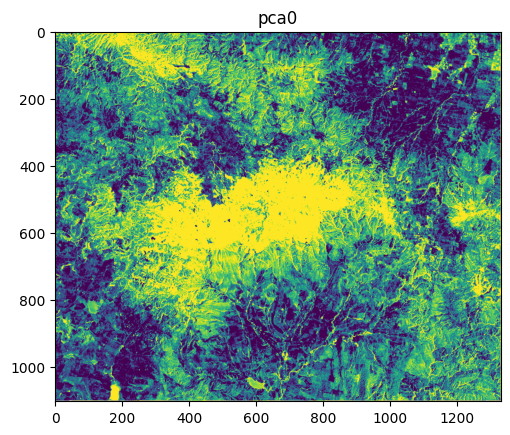

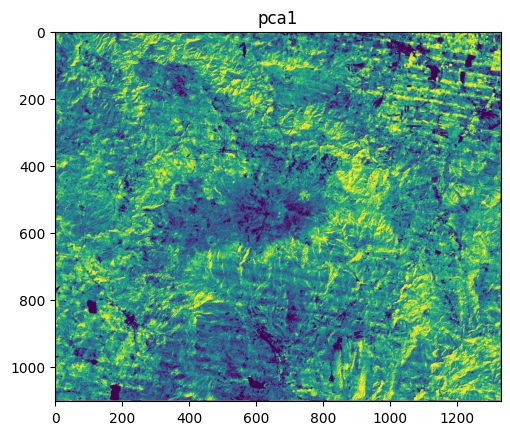

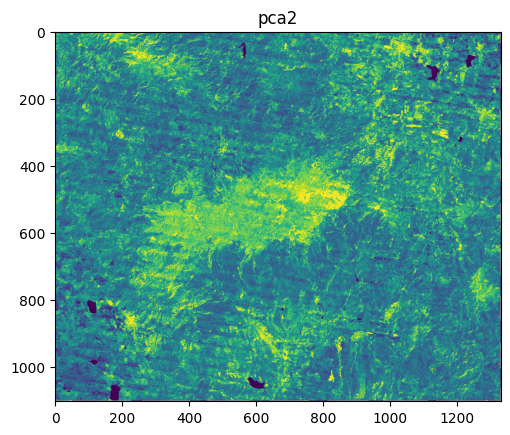

In [15]:
for sensor in SENSORES:
    arr = pca_resultados_ss[sensor]['transformed_array']
    orden = pca_resultados_ss[sensor]['orden_capas']
    print(f"\n{sensor}")
    print("-" * 40)

    for i in range(len(orden)):
        nombre = orden[i]
        capa = arr[i]
        valida = capa[~np.isnan(capa)]
        mediana = np.median(valida)
        promedio = np.mean(valida)
        sd = np.std(valida)
        q1 = np.percentile(valida, 25)
        q3 = np.percentile(valida, 75)
        print(f"{nombre}: promedio={promedio:.4f}  mediana={mediana:.4f}  SD={sd:.4f} IQR={q3 - q1:.4f}  min={valida.min():.4f}  max={valida.max():.4f}")


for sensor in SENSORES:
    arr = pca_resultados_ss[sensor]['transformed_array']
    orden = pca_resultados_ss[sensor]['orden_capas']
    print(f"\n{sensor}")
    print("-" * 40)

    plt.imshow(arr[0,:,:], vmin=-2.5, vmax=2.5)
    plt.title(orden[0])
    plt.show()

    plt.imshow(arr[1,:,:], vmin=-2.5, vmax=2.5)
    plt.title(orden[1])
    plt.show()

    plt.imshow(arr[2,:,:], vmin=-2.5, vmax=2.5)
    plt.title(orden[2])
    plt.show()